In [1]:
#pip install -r requirements.txt

In [2]:
import cartopy.crs as ccrs
import copy
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import networkx as nx 
import numpy as np
import os
import pandas as pd
import seaborn as sns
import sys
import textwrap


from collections import Counter
from io import BytesIO
from IPython.display import IFrame, Image, display
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from networkx.algorithms.community import louvain_communities
from pathlib import Path
from tqdm.notebook import tqdm

In [3]:
sys.path.append(os.getcwd())
sys.path.append(os.path.join(os.getcwd(), 'fuentes_de_datos'))

%load_ext autoreload
%autoreload 2
    
# Módulos nuestros
import funciones_auxiliares as fa
from fuentes_de_datos import conjunto_de_datos as cdd

1. Procesando regiones, subregiones y códigos de países...
Operación finalizada.
2. Procesando ubicaciones...
Operación finalizada.
3. Procesando datos de población...
Operación finalizada.
4. Procesando datos migratorios...
Operación finalizada.
5. Procesando datos económicos...
Operación finalizada.
6. Integrando los datos...
Operación finalizada.


# **Proximidad lingüística y pasado colonial en la subred de migraciones con orígen en África** 

***(EXTENSIÓN)***

## **Fuentes de datos**

**Idioma en común**: datos de localización del CLDR (*Common Locale Data Repository 48.2*) de *Unicode*. 


Data source and licensing

Source: Unicode Common Locale Data Repository (CLDR), version 48.2.

Data file: common/supplemental/supplementalData.xml

Copyright: © Unicode, Inc. (1991–2026).

License: Unicode License V3 (Unicode-3.0).

Source URL: https://raw.githubusercontent.com/unicode-org/cldr/release-48-2/common/supplemental/supplementalData.xml

License: https://github.com/unicode-org/cldr/blob/release-48-2/LICENSE




**Pasado colonial**: Becker, Bastian, 2019, "Colonial Dates Dataset (COLDAT)", https://doi.org/10.7910/DVN/T9SDEW, Harvard Dataverse.

### **Idioma en común**

In [4]:
# Obtenemos los datos de idioma en común entre países
import requests
import xml.etree.ElementTree as ET

url = 'https://raw.githubusercontent.com/unicode-org/cldr/release-48-2/common/supplemental/supplementalData.xml'
xml = requests.get(url)
xml.raise_for_status()
xml.status_code
if xml.status_code == 200:
    raiz = ET.fromstring(xml.text)
    filas = []
    for territorio in raiz.findall('.//territoryInfo/territory'):
        iso2 = territorio.attrib['type']
        for idioma in territorio.findall('languagePopulation'):
            if (
                idioma.attrib.get('officialStatus') == 'official' or
                idioma.attrib.get('officialStatus') == 'de_facto_official' 
            ):
                filas.append({
                    'iso2': iso2,
                    'idioma': idioma.attrib.get('type'),
                    'pct_hablante': idioma.attrib.get('populationPercent'),
                    'status': idioma.attrib.get('officialStatus'),
                })
df_idioma = pd.DataFrame(filas)
# df_idioma.head()

df_idioma_comun = (
    df_idioma.merge(df_idioma, on='idioma')
      .query('iso2_x != iso2_y')
      [['iso2_x', 'iso2_y']]
      .drop_duplicates()
      .rename(columns={
          'iso2_x': 'pais_A',
          'iso2_y': 'pais_B'
      })
)
df_idioma_comun['idioma_en_comun'] = True
display(df_idioma_comun)

,pais_A,pais_B,idioma_en_comun
2,AE,BH,True
3,AE,DJ,True
4,AE,DZ,True
5,AE,EG,True
6,AE,EH,True
...,...,...,...
11859,ZW,VI,True
11860,ZW,VU,True
11861,ZW,WS,True
11862,ZW,ZA,True


## **Pasado colonial**

### **Potencias coloniales europeas**

In [5]:
url_colonias = 'https://dataverse.harvard.edu/api/v1/access/datafile/7416947?gbrecs=false'

tab = requests.get(url_colonias)
tab.raise_for_status()
tab.status_code

if tab.status_code == 200:  
    df_diadas_original = pd.read_csv(BytesIO(tab.content), sep='\t')
    
df_diadas_coloniales = df_diadas_original[df_diadas_original["col"] == 1].copy()

# Listas con los nombres originales de países en la tabla
paises_colonizadores = df_diadas_coloniales['colonizer'].unique()
paises_colonizados = df_diadas_coloniales['country'].unique()

# Nos quedamos con las columnas de las diadas
df_diadas_coloniales = df_diadas_coloniales.iloc[:, :2].copy()


# Diccionarios para mapear los nombres originales de la tabla a codigos alfa2

# POTENCIAS
dicc_iso2_paises_colonizadores = {
    'belgium': 'BE',
    'britain': 'GB', 
    'france': 'FR',
    'germany': 'DE',
    'netherlands': 'NL',
    'portugal': 'PT',
    'spain': 'ES',
    'italy': 'IT',
}

# RESTO DEL MUNDO
dicc_iso2_paises = dict(zip(cdd.df_m49['pais_EN'], cdd.df_m49['iso2_m49']))

dicc_iso2_paises = (
    dicc_iso2_paises | # Actulizo los nombres que figuran distintos en el df original 
    {  
        'Cape Verde': 'CV',
        'Congo - Brazzaville': 'CG',
        'Congo - Kinshasa': 'CD',
        'São Tomé & Príncipe': 'ST',
        'Tanzania': 'TZ',
        'Antigua & Barbuda': 'AG',
        'Bolivia': 'BO',
        'St. Lucia': 'LC',
        'Syria': 'SY',
        'Trinidad & Tobago': 'TT',
        'United States': 'US',
        'Venezuela': 'VE',
        'Brunei': 'BN',
        'Myanmar (Burma)': 'MM',
        'Nauru': 'NR',
        'St. Kitts & Nevis': 'KN',
        'St. Vincent & Grenadines': 'VC',
        'Laos': 'LA',
        'Vietnam': 'VN',
        'Nauru': 'NR',
    }
)

# Para renombrar los paises a códigos alfa2
def renombrar_con_dicc(fila, columna, dicc):
    valor = fila[columna]
    return dicc.get(valor, valor)

df_diadas_coloniales['iso2_pais'] = (
    df_diadas_coloniales.apply(
        renombrar_con_dicc,
        dicc=dicc_iso2_paises,
        columna='country',
        axis=1
    )
)

df_diadas_coloniales['iso2_colonizador'] = (
    df_diadas_coloniales.apply(
        renombrar_con_dicc,
        dicc=dicc_iso2_paises_colonizadores,
        columna='colonizer',
        axis=1
    )
)

df_diadas_coloniales = df_diadas_coloniales.iloc[:, 2:].copy().reset_index(drop=True)

display(df_diadas_coloniales)

,iso2_pais,iso2_colonizador
0,BI,BE
1,CD,BE
2,RW,BE
3,AG,GB
4,AU,GB
...,...,...
156,UY,ES
157,VE,ES
158,ER,IT
159,LY,IT


### **Ex-colonias de una misma Potencia Colonial**

In [6]:
df = df_diadas_coloniales.copy()

df_metropoli_comun = (
    df.merge(
        df,
        on="iso2_colonizador",
        suffixes=("_A", "_B")
    )
    [["iso2_pais_A", "iso2_pais_B"]]
)

# Elimino los pares pais-pais
df_metropoli_comun = df_metropoli_comun[
    df_metropoli_comun["iso2_pais_A"] != df_metropoli_comun["iso2_pais_B"]
].reset_index(drop=True)

df_metropoli_comun['metropoli_comun'] = True
display(df_metropoli_comun)

,iso2_pais_A,iso2_pais_B,metropoli_comun
0,BI,CD,True
1,BI,RW,True
2,CD,BI,True
3,CD,RW,True
4,RW,BI,True
...,...,...,...
6545,ER,SO,True
6546,LY,ER,True
6547,LY,SO,True
6548,SO,ER,True


## **Red de migraciones con origen en África**

In [7]:
AÑOS = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024]

df_migras_orig_africa = (
    cdd.df_migras_90_24.query("region_orig_EN == 'Africa'")
    .copy()
    .reset_index(drop=True)
)

# Agrego columna que indica si el movimiento es hacia idioma en común
pares_idioma = set(zip(df_idioma_comun['pais_A'], df_idioma_comun['pais_B']))
df_migras_orig_africa['idioma_en_comun'] = [
    p in pares_idioma 
    for p in zip(df_migras_orig_africa['iso2_orig'], df_migras_orig_africa['iso2_des'])
]

# Agrego columna que indica si el movimiento es hacia la antigua Potencia COlonial
pares_colonia = (
    set(zip(
        df_diadas_coloniales['iso2_pais'], 
        df_diadas_coloniales['iso2_colonizador']
    ))
)
df_migras_orig_africa['a_colonizador'] = [
    p in pares_colonia 
    for p in zip(df_migras_orig_africa['iso2_orig'], df_migras_orig_africa['iso2_des'])
]

# Agrego columna que indica si el movimiento es hacia ex colonias de una misma potencia
pares_metro_comun = set(zip(df_metropoli_comun['iso2_pais_A'], df_metropoli_comun['iso2_pais_B']))
df_migras_orig_africa['metropoli_comun'] = [
    p in pares_metro_comun
    for p in zip(df_migras_orig_africa['iso2_orig'], df_migras_orig_africa['iso2_des'])
]

df_migras_orig_africa.head()

,cod_orig,iso2_orig,iso3_orig,origen_ES,origen_EN,region_orig_ES,region_orig_EN,subregion_orig_ES,subregion_orig_EN,poblacion_orig,...,poblacion_des,menos_desarr_des,sin_litoral_des,lon_des,lat_des,año,migrantes,idioma_en_comun,a_colonizador,metropoli_comun
0,24,AO,AGO,Angola,Angola,África,Africa,África Subsahariana,Sub-Saharan Africa,11626000.0,...,2032000.0,True,False,38.111131,16.136251,1990,247,False,False,False
1,24,AO,AGO,Angola,Angola,África,Africa,África Subsahariana,Sub-Saharan Africa,11626000.0,...,13094000.0,True,False,38.184799,-14.299570,1990,14337,True,False,True
2,24,AO,AGO,Angola,Angola,África,Africa,África Subsahariana,Sub-Saharan Africa,11626000.0,...,26110000.0,True,False,34.810819,-6.286272,1990,717,False,False,False
3,24,AO,AGO,Angola,Angola,África,Africa,África Subsahariana,Sub-Saharan Africa,11626000.0,...,7786000.0,True,True,27.852457,-14.609518,1990,123807,False,False,False
4,24,AO,AGO,Angola,Angola,África,Africa,África Subsahariana,Sub-Saharan Africa,11626000.0,...,2380000.0,False,False,15.240111,-0.831270,1990,10334,False,False,False


### **Migración y población**

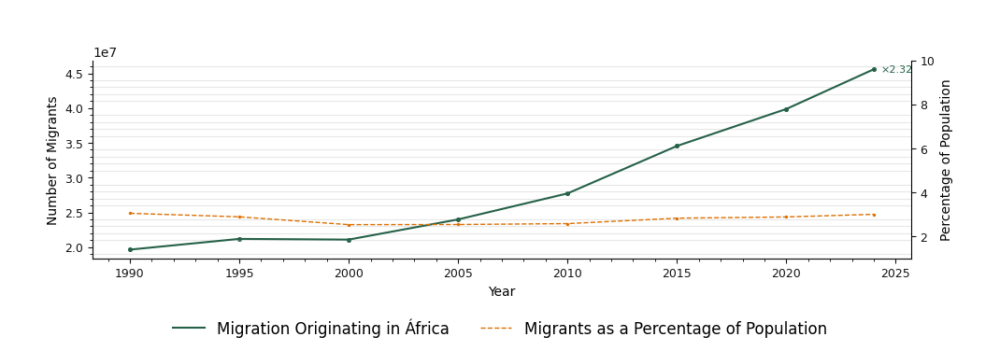

,año,total_migra,total_pobla,pct_pobla_migrante
0,1990,19651070,642995000,3.056178
1,1995,21195019,731832000,2.896159
2,2000,21091917,829632000,2.542322
3,2005,23991245,941540000,2.548086
4,2010,27729763,1071130000,2.588833
5,2015,34551971,1218933000,2.834608
6,2020,39872223,1379644000,2.890037
7,2024,45587836,1513902000,3.011281


In [8]:
iso3_paises_africa = cdd.df_m49.query("region_EN == 'Africa'")['iso3_m49'].to_list()

total_migra = []
total_pobla = []

for año in AÑOS:
    df_año = df_migras_orig_africa.query('año == @año')
    total_migra.append(df_año['migrantes'].sum())
    
    poblacion_total = int(
        cdd.df_poblaciones.loc[
            (cdd.df_poblaciones['iso3_pobla'].isin(iso3_paises_africa)) &
            (cdd.df_poblaciones['año_pobla'] == año),
            'poblacion'
        ].sum()
    )
    total_pobla.append(poblacion_total)

pct_pobla_migrante = [
    100 * migra/pobla 
    for migra, pobla in zip(total_migra, total_pobla)
]

df_migra_af_totales = pd.DataFrame({
    'año': AÑOS,
    'total_migra': total_migra,
    'total_pobla': total_pobla,
    'pct_pobla_migrante': pct_pobla_migrante,     
})

dicc_tex_ref = {
    'total_migra': 'Migration Originating in África',#'Migración con origen en África',
    'pct_pobla_migrante': 'Migrants as a Percentage of Population',#'Porcentaje migrante de su población',
}
colores_var = {'total_migra': '#256148', 'pct_pobla_migrante': '#dd7003'}
# args = {'config_lim_y': False, 'lim_eje_y': (1e7, 5e7)}

fig = fa.graficar_migras_poblacion(
    df_migra_af_totales,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes',
    colores_var,
    'migracion_y_poblacion_af',
    **{}
)
display(fig)
display(df_migra_af_totales)

### **Direcciones de la migración con origen en África**

Veficación de que la clasificación es exhaustiva y no se superponen categorías.

In [90]:
df_migras_orig_africa.query('metropoli_comun & a_colonizador')

,cod_orig,iso2_orig,iso3_orig,origen_ES,origen_EN,region_orig_ES,region_orig_EN,subregion_orig_ES,subregion_orig_EN,poblacion_orig,...,poblacion_des,menos_desarr_des,sin_litoral_des,lon_des,lat_des,año,migrantes,idioma_en_comun,a_colonizador,metropoli_comun


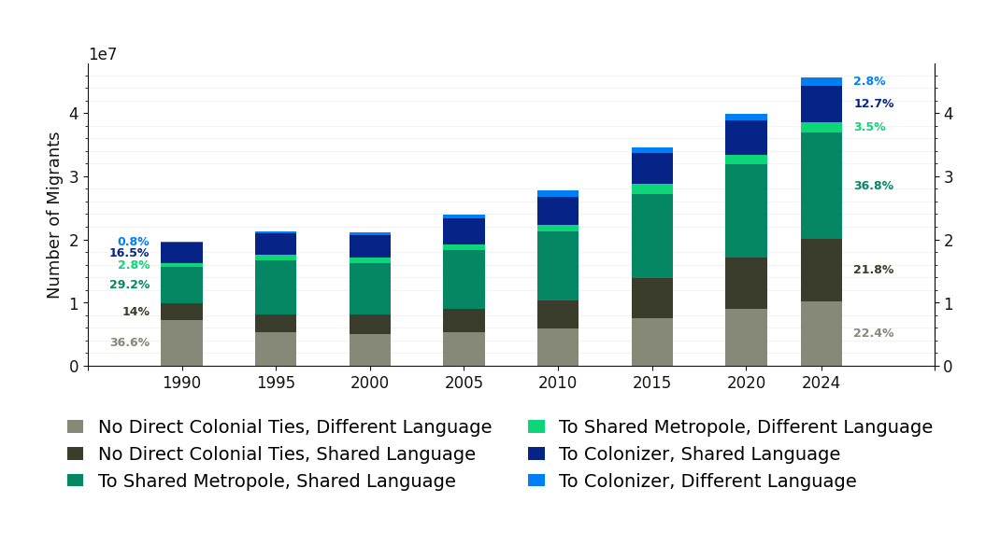

,año,migra_colon_comun,migra_colon_otro,migra_metro_comun,migra_metro_otro,migra_novin_comun,migra_novin_otro,total
0,1990,3241932,164382,5745832,554612,2760080,7184232,19651070
1,1995,3383009,241966,8597556,857462,2864020,5251006,21195019
2,2000,3647509,380685,8209315,771596,2999276,5083536,21091917
3,2005,4154346,677649,9305278,885841,3663896,5304235,23991245
4,2010,4463945,932285,10827134,1134364,4509875,5862160,27729763
5,2015,4907934,915615,13344239,1483756,6407368,7493059,34551971
6,2020,5392792,1104173,14732212,1526350,8144291,8972405,39872223
7,2024,5771833,1290497,16775813,1598906,9933555,10217232,45587836


In [58]:
# Obtenemos el número de migrantes en cada posible dirección
migra_af_col_ic = [] # a colonizador - idioma comun 
migra_af_col_io = [] # a colonizador - otro idioma  
migra_af_met_ic = [] # a metro_comun - idioma comun
migra_af_met_io = [] # a metro_comun - otro idioma
migra_af_novin_ic = [] # a no_vinc_col - idioma comun
migra_af_novin_io = [] # a no_vinc_col - otro idioma

def clasificar_migracion_africa(fila):
    # Hay dos combinaciones que no se cumplen: 
    # a colonizador y a metrópoli común indep. del idioma (simplifcar condiciones)
    if fila['a_colonizador'] and not fila['metropoli_comun'] and fila['idioma_en_comun']:
        return 'COL-IC'
    elif fila['a_colonizador'] and not fila['metropoli_comun'] and not fila['idioma_en_comun']:
        return 'COL-IO'    
        
    elif not fila['a_colonizador'] and fila['metropoli_comun'] and fila['idioma_en_comun']:
        return 'MET-IC'    
    elif not fila['a_colonizador'] and fila['metropoli_comun'] and not fila['idioma_en_comun']:
        return 'MET-IO'
    
    elif not fila['a_colonizador'] and not fila['metropoli_comun'] and fila['idioma_en_comun']:
        return 'NOVIN-IC'    
    elif not fila['a_colonizador'] and not fila['metropoli_comun'] and not fila['idioma_en_comun']:
        return 'NOVIN-IO'
    else:
        raise ValueError(f"Caso no contemplado: {fila}")

# Desglose por anitgua potencia colonial
ex_col_migras_a_BE = []
ex_col_migras_a_GB = []
ex_col_migras_a_FR = []
ex_col_migras_a_DE = []
ex_col_migras_a_NL = []
ex_col_migras_a_PT = []
ex_col_migras_a_ES = []
ex_col_migras_a_IT = []

for año in AÑOS:
    df_año = df_migras_orig_africa.query('año == @año').copy()
    df_año['tipo_migra'] = df_año.apply(clasificar_migracion_africa, axis=1)    
    migra_af_col_ic.append(df_año.query("tipo_migra == 'COL-IC'")['migrantes'].sum())
    migra_af_col_io.append(df_año.query("tipo_migra == 'COL-IO'")['migrantes'].sum())    
    migra_af_met_ic.append(df_año.query("tipo_migra == 'MET-IC'")['migrantes'].sum())
    migra_af_met_io.append(df_año.query("tipo_migra == 'MET-IO'")['migrantes'].sum())    
    migra_af_novin_ic.append(df_año.query("tipo_migra == 'NOVIN-IC'")['migrantes'].sum())
    migra_af_novin_io.append(df_año.query("tipo_migra == 'NOVIN-IO'")['migrantes'].sum())

    # Desagrego por anitgua potencia colonial 
    ex_col_migras_a_BE.append(df_año.query("iso2_des == 'BE' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_GB.append(df_año.query("iso2_des == 'GB' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_FR.append(df_año.query("iso2_des == 'FR' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_DE.append(df_año.query("iso2_des == 'DE' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_NL.append(df_año.query("iso2_des == 'NL' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_PT.append(df_año.query("iso2_des == 'PT' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_ES.append(df_año.query("iso2_des == 'ES' & a_colonizador")['migrantes'].sum())
    ex_col_migras_a_IT.append(df_año.query("iso2_des == 'IT' & a_colonizador")['migrantes'].sum())


# En este df guardo las migraciones a potencias coloniales
# exclusivamente desde países colonizados
df_migras_a_potencias = pd.DataFrame({
    'año': AÑOS,
    'migras_a_BE': ex_col_migras_a_BE,
    'migras_a_GB': ex_col_migras_a_GB,
    'migras_a_FR': ex_col_migras_a_FR,
    'migras_a_DE': ex_col_migras_a_DE,    
    'migras_a_NL': ex_col_migras_a_NL,
    'migras_a_PT': ex_col_migras_a_PT,
    'migras_a_ES': ex_col_migras_a_ES,
    'migras_a_IT': ex_col_migras_a_IT,
})


# Df con las migraciones en cada direccion
df_compar_direcciones_migra_af = pd.DataFrame({
    'año': AÑOS,
    'migra_colon_comun': migra_af_col_ic,
    'migra_colon_otro': migra_af_col_io,
    'migra_metro_comun': migra_af_met_ic,
    'migra_metro_otro': migra_af_met_io,    
    'migra_novin_comun': migra_af_novin_ic,
    'migra_novin_otro': migra_af_novin_io,
})
# Agrego el total en cada año
df_compar_direcciones_migra_af['total'] = df_compar_direcciones_migra_af.iloc[:, 1:].sum(axis=1)

# Configuración de la visualización
dicc_tex_ref = {    
    'migra_colon_comun': 'To Colonizer, Shared Language',
    'migra_colon_otro': 'To Colonizer, Different Language',
    'migra_metro_comun': 'To Shared Metropole, Shared Language',
    'migra_metro_otro': 'To Shared Metropole, Different Language',  
    'migra_novin_comun': 'No Direct Colonial Ties, Shared Language',
    'migra_novin_otro': 'No Direct Colonial Ties, Different Language',
}
colores_var = {
    'migra_novin_otro': '#868878',#'#8e9e8b',
    'migra_novin_comun': '#3b3d2c', 
    'migra_metro_comun': '#068763', 
    'migra_metro_otro': '#0dd678',#'#d1b039',
    'migra_colon_comun': '#062487',          
    'migra_colon_otro': '#007ff5',
}
args = {
    'tam_tex_pct': 9,
    'tam_marcas_ejes': 12,
    'tam_ref': 14,
    'ubicacion_refs': (.5, -.27),
    'grosor_barras': 2.2,
    'margen_etq_pct': 1.7,
}

# Barras apiladas
fig_red_africa, _ = fa.graficar_barras_migras(
    df_compar_direcciones_migra_af,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_direcciones_af',
    **args
)
# Muestro el gráfico y la tabla con datosb
display(fig_red_africa)
display(df_compar_direcciones_migra_af)

##### **Composición de la red migratoria con origen en África**

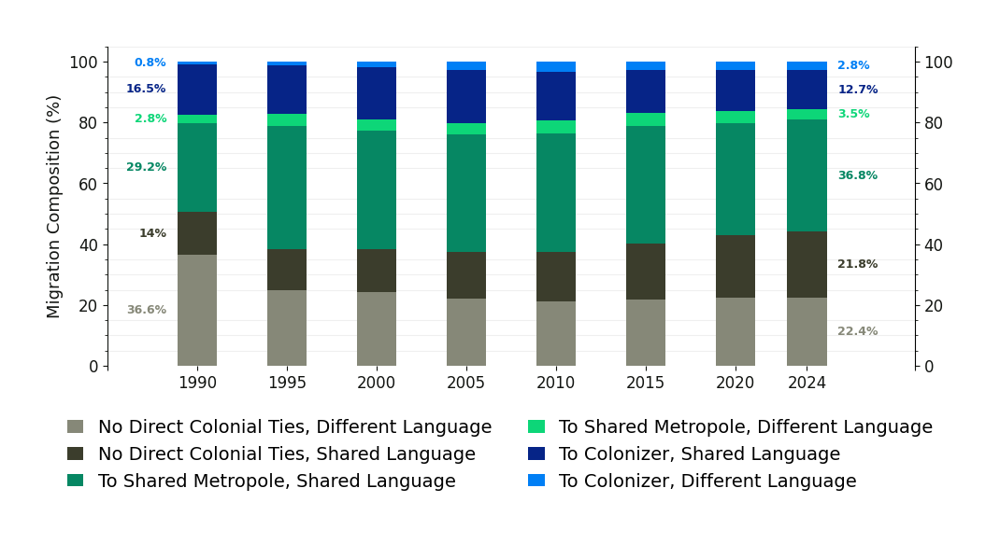

In [11]:
# Configuración de la visualización
dicc_tex_ref = {    
    'migra_colon_comun': 'To Colonizer, Shared Language',
    'migra_colon_otro': 'To Colonizer, Different Language',
    'migra_metro_comun': 'To Shared Metropole, Shared Language',
    'migra_metro_otro': 'To Shared Metropole, Different Language',  
    'migra_novin_comun': 'No Direct Colonial Ties, Shared Language',
    'migra_novin_otro': 'No Direct Colonial Ties, Different Language',
}

colores_var = {
    'migra_novin_otro': '#868878',#'#8e9e8b',
    'migra_novin_comun': '#3b3d2c', 
    'migra_metro_comun': '#068763', 
    'migra_metro_otro': '#0dd678',#'#d1b039',
    'migra_colon_comun': '#062487',          
    'migra_colon_otro': '#007ff5',
}
args = {
    'tam_tex_pct': 9,
    'tam_marcas_ejes': 12,
    'tam_ref': 14,
    'ubicacion_refs': (.5, -.27),
    'grosor_barras': 2.2,
    'margen_etq_pct': 1.7,
}


# Barras 100 pct
fig_red_africa, _ = fa.graficar_composicion_migras(
    df_compar_direcciones_migra_af,
    dicc_tex_ref,
    'Migration Composition (%)',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_direcciones_af_100pct',
    **args
)
# Muestro el gráfico y la tabla con datosb
display(fig_red_africa)

#### **Migraciones de ex-colonias a sus antiguas Potencias**

In [12]:
display(df_migras_a_potencias)

,año,migras_a_BE,migras_a_GB,migras_a_FR,migras_a_DE,migras_a_NL,migras_a_PT,migras_a_ES,migras_a_IT
0,1990,50447,268666,2664273,0,8562,258561,99697,56108
1,1995,53720,352492,2695222,0,9458,287105,169610,57368
2,2000,57537,483973,2806725,0,10949,327301,284929,56780
3,2005,78713,629057,3152384,0,12250,338517,565274,55800
4,2010,97878,833554,3314977,0,12881,293523,787355,56062
5,2015,104844,940223,3619172,0,13669,332761,755849,57031
6,2020,110192,1038958,3954688,0,20331,382021,936086,54689
7,2024,118256,1114649,4204763,0,31024,429766,1112780,51092


**Alemania (DE)**

En los registros de la ONU, la migración con origen en África dirigida hacia Alemania proviene de países que no fueron colonizados por este país, en particular de Marruecos. En 2024, se registraron **más de 3 millones de inmigrantes con origen desconocido en Alemania**. Es posible que el resto de la inmigración africana esté contenida en la categoría *'Otros'* (ZZ), o subrepresentada.

In [13]:
display(
    cdd.df_migras_90_24.query(
        "iso2_des == 'DE' & region_orig_EN =='Africa'"
    )[['iso2_orig', 'origen_EN', 'iso2_des', 'destino_EN', 'migrantes', 'año']]
)

display(cdd.df_migras_90_24.query("iso2_des == 'DE' & iso2_orig == 'ZZ'")[['iso2_orig', 'iso2_des', 'migrantes', 'año']])

,iso2_orig,origen_EN,iso2_des,destino_EN,migrantes,año
37215,MA,Morocco,DE,Germany,51179,1990
37267,MA,Morocco,DE,Germany,77959,1995
37319,MA,Morocco,DE,Germany,88300,2000
37372,MA,Morocco,DE,Germany,90887,2005
37427,MA,Morocco,DE,Germany,92469,2010
37484,MA,Morocco,DE,Germany,107252,2015
37541,MA,Morocco,DE,Germany,126665,2020
37598,MA,Morocco,DE,Germany,156555,2024


,iso2_orig,iso2_des,migrantes,año
63936,ZZ,DE,2178079,1990
64133,ZZ,DE,3407639,1995
64330,ZZ,DE,3592227,2000
64527,ZZ,DE,3953583,2005
64725,ZZ,DE,3726281,2010
64924,ZZ,DE,3400119,2015
65123,ZZ,DE,3868970,2020
65322,ZZ,DE,3137259,2024


# **Proximidad lingüística y pasado colonial en la subred de migraciones con orígen en la *Commonwealth (CW)***

**MIEMBROS**

Durante el período 1990-2024, se sumaron y retiraron países miembros de la asociación:

 - Zimbabwe (se retiró en 2003).
 - Togo (ingresó en 2022).
 - Rwanda (ingresó en 2009).
 - Gabón (ingresó en 2022).
 - Camerún (ingresó en 1995).
 - Mozambique (ingresó en 1995).

**El análisis incluye a los 56 miembros actuales**, aunque no hayan sido parte de la asociación en 1990.

**DATOS MIGRATORIOS**

Trabajamos con el **subconjunto de datos migratorios que tiene a los miembros como origen o destino**. Registramos para cada miembro y en cada año el porcentaje de datos sin origen observable, para tener una noción de la cobertura de los datos. 


**PROXIMIDAD LINGÜÍSTICA**

Utilizamos el **idioma oficial** o **de facto oficial** para definir si dos países/territorios tienen idioma en común. Usamos los datos de localización del CLDR (*Common Locale Data Repository 48.2*) de *Unicode*.

**PASADO COLONIAL**

Según Loft (2023), de los 56 países que son actualmente miembros de la asociación, **solo Rwanda, Mozambique, Gabón y Togo no formaron parte del Imperio Británico**.

Loft, P. (2023, 7 de marzo). The Commonwealth (Research Briefing No. CBP-9478). House of Commons Library. https://researchbriefings.files.parliament.uk/documents/CBP-9478/CBP-9478.pdf

## **Preparación de los datos**

In [14]:
# Lista de miembros de la Mancomunidad de NAciones
LISTA_MIEMBROS_CW = [
    # ÁFRICA
    'BW', 'CM', 'GA', 'GM', 'GH', 'KE', 'SZ', 'LS', 
    'MW', 'MU', 'MZ', 'NA', 'NG', 'RW', 'SC', 'SL',
    'ZA', 'TG', 'UG', 'TZ', 'ZM',
    # ASIA
    'BD', 'BN', 'IN', 'MY', 'MV', 'PK', 'SG', 'LK',
    # AMÉRICA
    'AG', 'BS', 'BB', 'BZ', 'CA', 'DM', 'GD', 'GY', 
    'JM', 'LC', 'KN', 'VC', 'TT',
    # EUROPA
    'CY', 'MT', 'GB',
    # OCEANIA
    'AU',  'FJ', 'KI', 'NR', 'NZ', 'PG', 'WS', 'SB',
    'TO', 'TV', 'VU',
]
CONJ_MIEMBROS_CW = set(LISTA_MIEMBROS_CW)

DICC_NOMBRES_MIEMBROS_CW = {
    p: cdd.df_m49.query('iso2_m49 == @p')['pais_EN'].iloc[0]
    for p in LISTA_MIEMBROS_CW
}

DICC_ISO3_MIEMBROS_CW = {
    p: cdd.df_m49.query('iso2_m49 == @p')['iso3_m49'].iloc[0]
    for p in LISTA_MIEMBROS_CW
}

DICC_NOMBRES_PAISES = {
    p: cdd.df_m49.query('iso2_m49 == @p')['pais_EN'].iloc[0]
    for p in cdd.df_m49['iso2_m49'].unique()
}


# Países que no formaron parte del Imperio Británico
CONJ_NO_IB = {'RW', 'GA', 'MZ', 'TG'}
CONJ_COLONIAS_IB = CONJ_MIEMBROS_CW - CONJ_NO_IB


AÑOS = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024]

print(len(LISTA_MIEMBROS_CW), 'miembros')

56 miembros


In [15]:
# Diccionario datos sin trazabilidad {país: [x%, ..., x%]} (lista con pct de ZZ por año)
dicc_sin_traza = {} 

# DF con las migraciones por año
df_migras_cw = pd.DataFrame()
for año in AÑOS:
    df_año = cdd.df_migras_90_24.query('año == @año').copy()

    for pais in LISTA_MIEMBROS_CW:
        df_pais = df_año.query('iso2_orig == @pais | iso2_des == @pais').copy()    
        tot_inmigrantes = df_pais.query('iso2_des == @pais').migrantes.sum()
        tot_otros = df_pais.query("iso2_orig == 'ZZ'").migrantes.sum()        
        dicc_sin_traza.setdefault(pais, []).append(round(100*tot_otros/tot_inmigrantes,2))
        
        if len(df_pais) > 0:
            df_migras_cw = pd.concat([df_migras_cw, df_pais])

# Contiene las migraciones desde y hacia países miembros del CW          
df_migras_cw = df_migras_cw.reset_index(drop=True)

### **Cobertura**

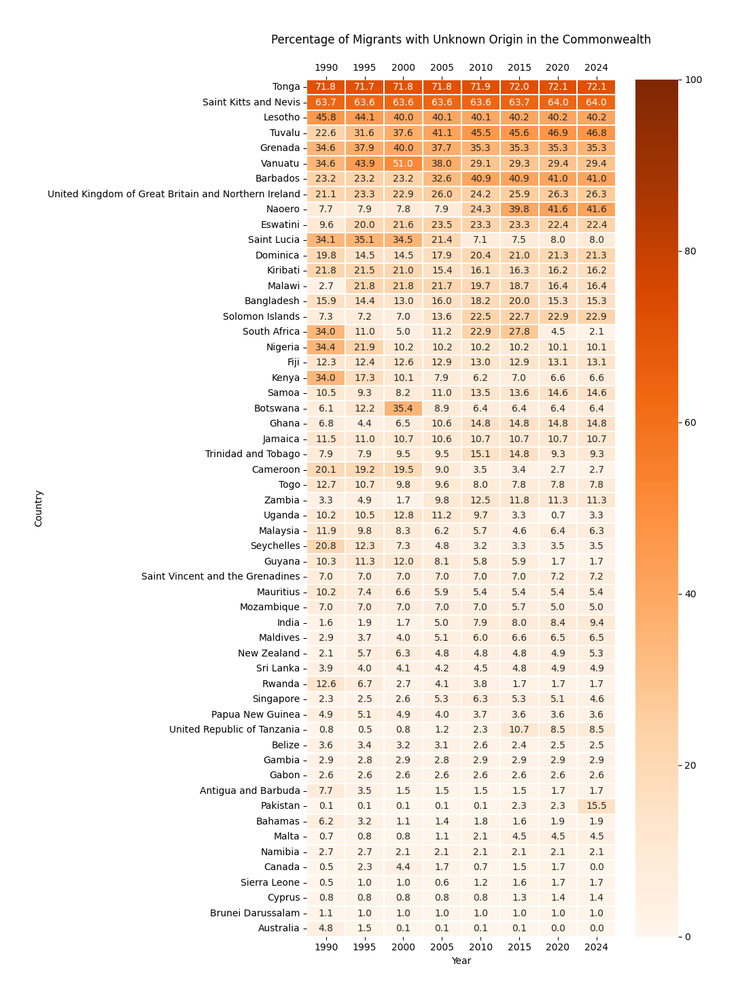

In [16]:
df = pd.DataFrame.from_dict(
    dicc_sin_traza,
    orient='index',
    columns=AÑOS
)

df.index = df.index.map(DICC_NOMBRES_MIEMBROS_CW)

# Ordenar países por porcentaje promedio de datos sin trazabilidad
df = df.loc[df.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(10, 14))
ax = sns.heatmap(
    df,
    cmap='Oranges',
    vmin=0,
    vmax=100,
    annot=True,
    fmt='.1f',
    linewidths=0.3
)

ax.tick_params(
    axis='x',
    top=True,
    bottom=True,
    labeltop=True,
    labelbottom=True
)

plt.xlabel('Year')
plt.ylabel('Country')
# plt.title('Porcentaje migrantes de origen desconocido en la Commonwealth')
plt.title('Percentage of Migrants with Unknown Origin in the Commonwealth\n')
plt.tight_layout()
plt.show()

### **Idioma en común**

Para agregar a las migraciones si los países de origen y destino comparten idioma oficial o de facto en común, utilizamos los datos de localización del CLDR (*Common Locale Data Repository 48.2*) de *Unicode*.

In [17]:
# Obtenemos los datos de idioma en común entre países
import requests
import xml.etree.ElementTree as ET

url = 'https://raw.githubusercontent.com/unicode-org/cldr/release-48-2/common/supplemental/supplementalData.xml'
xml = requests.get(url)
xml.raise_for_status()
xml.status_code
if xml.status_code == 200:
    raiz = ET.fromstring(xml.text)
    filas = []
    for territorio in raiz.findall('.//territoryInfo/territory'):
        iso2 = territorio.attrib['type']
        for idioma in territorio.findall('languagePopulation'):
            if (
                idioma.attrib.get('officialStatus') == 'official' or
                idioma.attrib.get('officialStatus') == 'de_facto_official' 
            ):
                filas.append({
                    'iso2': iso2,
                    'idioma': idioma.attrib.get('type'),
                    'pct_hablante': idioma.attrib.get('populationPercent'),
                    'status': idioma.attrib.get('officialStatus'),
                })
df_idioma = pd.DataFrame(filas)
# df_idioma.head()

df_idioma_comun = (
    df_idioma.merge(df_idioma, on='idioma')
      .query('iso2_x != iso2_y')
      [['iso2_x', 'iso2_y']]
      .drop_duplicates()
      .rename(columns={
          'iso2_x': 'pais_A',
          'iso2_y': 'pais_B'
      })
)
df_idioma_comun['idioma_en_comun'] = True
# df_idioma_comun.head()

## **Red de migraciones con origen en la Commonwealth**

In [18]:
# Datos migratorios con origen en países miembros 
df_migras_orig_cw = ( 
    df_migras_cw[df_migras_cw['iso2_orig'].isin(CONJ_MIEMBROS_CW)]
    .copy()
    .reset_index(drop=True)
)

# Agrego columna que indica si el movimiento es hacia un destino con idioma en común
pares_idioma = set(zip(df_idioma_comun['pais_A'], df_idioma_comun['pais_B']))
df_migras_orig_cw['idioma_en_comun'] = [
    p in pares_idioma 
    for p in zip(df_migras_orig_cw['iso2_orig'], df_migras_orig_cw['iso2_des'])
]

# Agrego columna que indica si el movimiento es hacia una antigua Potencia Colonial
pares_colonia = set(zip(df_diadas_coloniales['iso2_pais'], df_diadas_coloniales['iso2_colonizador']))
df_migras_orig_cw['a_colonizador'] = [
    p in pares_colonia 
    for p in zip(df_migras_orig_cw['iso2_orig'], df_migras_orig_cw['iso2_des'])
]

# Agrego columna que indica si el movimiento es desde una antigua Potencia COlonial (GB)
df_migras_orig_cw['de_colonizador'] = (
    (df_migras_orig_cw['iso2_orig'] == 'GB') & 
    (df_migras_orig_cw['iso2_des'].isin(CONJ_COLONIAS_IB))
)


# Agrego columna que indica si el movimiento es hacia ex colonias de una misma potencia
df_migras_orig_cw['metropoli_comun'] = [
    p in pares_metro_comun
    for p in zip(df_migras_orig_cw['iso2_orig'], df_migras_orig_cw['iso2_des'])
]

df_migras_orig_cw.head()

,cod_orig,iso2_orig,iso3_orig,origen_ES,origen_EN,region_orig_ES,region_orig_EN,subregion_orig_ES,subregion_orig_EN,poblacion_orig,...,menos_desarr_des,sin_litoral_des,lon_des,lat_des,año,migrantes,idioma_en_comun,a_colonizador,de_colonizador,metropoli_comun
0,36,AU,AUS,Australia,Australia,Oceanía,Oceania,Australia y Nueva Zelandia,Australia and New Zealand,17126000.0,...,False,True,23.808412,-22.236004,1990,120,True,False,False,True
1,72,BW,BWA,Botswana,Botswana,África,Africa,África Subsahariana,Sub-Saharan Africa,1305000.0,...,True,False,34.810819,-6.286272,1990,80,True,False,False,True
2,72,BW,BWA,Botswana,Botswana,África,Africa,África Subsahariana,Sub-Saharan Africa,1305000.0,...,True,True,27.852457,-14.609518,1990,469,True,False,False,True
3,72,BW,BWA,Botswana,Botswana,África,Africa,África Subsahariana,Sub-Saharan Africa,1305000.0,...,False,True,29.869061,-19.023587,1990,2945,True,False,False,True
4,72,BW,BWA,Botswana,Botswana,África,Africa,África Subsahariana,Sub-Saharan Africa,1305000.0,...,False,True,31.501514,-26.566696,1990,161,True,False,False,True


### **Migración y población**

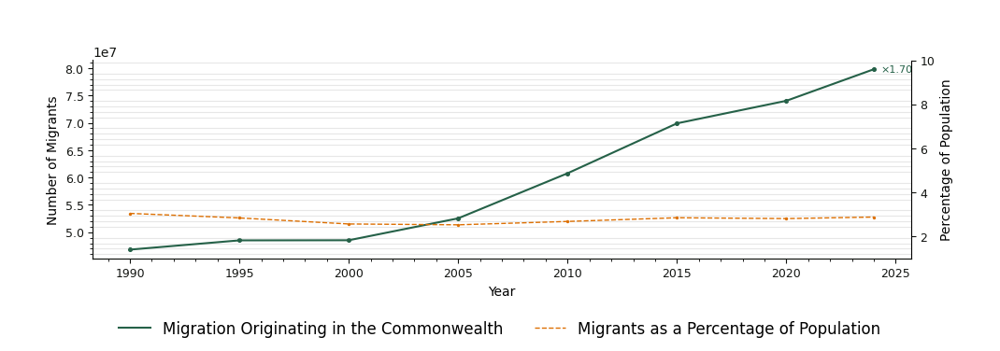

,año,total_migra,total_pobla,pct_pobla_migrante
0,1990,46824773,1534128000,3.052208
1,1995,48514175,1704584000,2.846101
2,2000,48537002,1886801000,2.572449
3,2005,52540929,2073073000,2.534447
4,2010,60775661,2261903000,2.686926
5,2015,69898508,2448568000,2.854669
6,2020,74024176,2628190000,2.816546
7,2024,79790686,2765038000,2.885699


In [19]:
iso3_miembros_cw = DICC_ISO3_MIEMBROS_CW.values()

total_migra = []
total_pobla = []

for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año')
    total_migra.append(df_año['migrantes'].sum())
    
    poblacion_total = int(
        cdd.df_poblaciones.loc[
            (cdd.df_poblaciones['iso3_pobla'].isin(iso3_miembros_cw)) &
            (cdd.df_poblaciones['año_pobla'] == año),
            'poblacion'
        ].sum()
    )
    total_pobla.append(poblacion_total)

pct_pobla_migrante = [
    100 * migra/pobla 
    for migra, pobla in zip(total_migra, total_pobla)
]

df_migra_cw_totales = pd.DataFrame({
    'año': AÑOS,
    'total_migra': total_migra,
    'total_pobla': total_pobla,
    'pct_pobla_migrante': pct_pobla_migrante,     
})

dicc_tex_ref = {
    'total_migra': 'Migration Originating in the Commonwealth',#'Migración con origen en la Commonwealth',
    'pct_pobla_migrante': 'Migrants as a Percentage of Population',#'Porcentaje migrante de su población',
}
colores_var = {'total_migra': '#256148', 'pct_pobla_migrante': '#dd7003'}
args = {'config_lim_y': True,}

fig = fa.graficar_migras_poblacion(
    df_migra_cw_totales,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes',
    colores_var,
    'migracion_y_poblacion_cw',
)
display(fig)
display(df_migra_cw_totales)

### **Métricas de la red**

,año,nodos,enlaces,density,reciprocity,promedio_in_out_degree,desvio_in_degree,desvio_out_degree
0,1990,180,1733,0.0538,0.2239,9.63,9.89,20.36
1,1995,182,1791,0.0544,0.2189,9.84,10.57,20.53
2,2000,183,1811,0.0544,0.2165,9.90,10.49,20.74
3,2005,183,1845,0.0554,0.2157,10.08,10.84,20.98
4,2010,184,1925,0.0572,0.2068,10.46,11.12,21.55
5,2015,184,2027,0.0602,0.1963,11.02,12.18,21.86
6,2020,184,1998,0.0593,0.1992,10.86,11.55,21.96
7,2024,184,1998,0.0593,0.1992,10.86,11.55,21.95


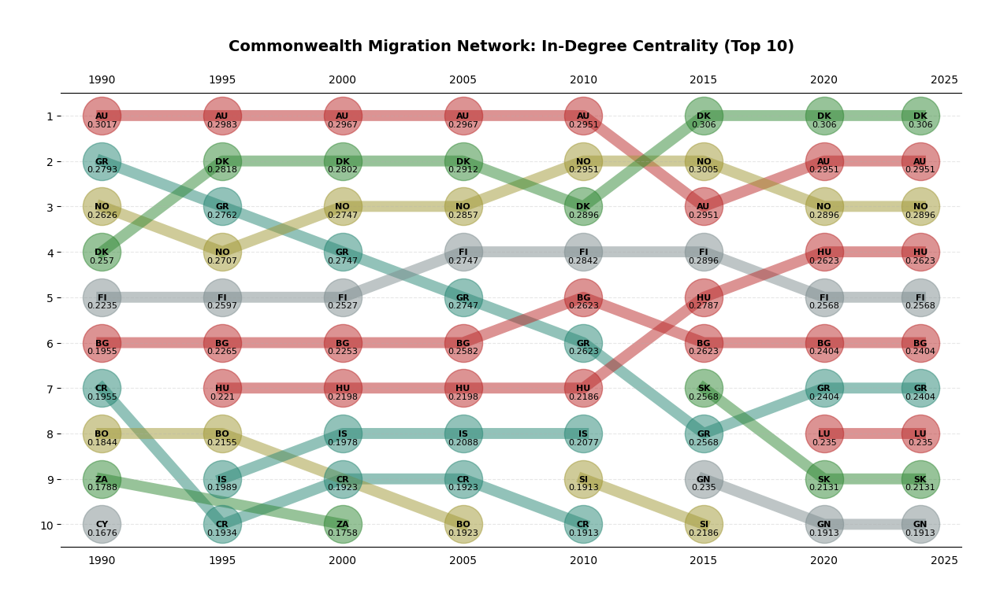

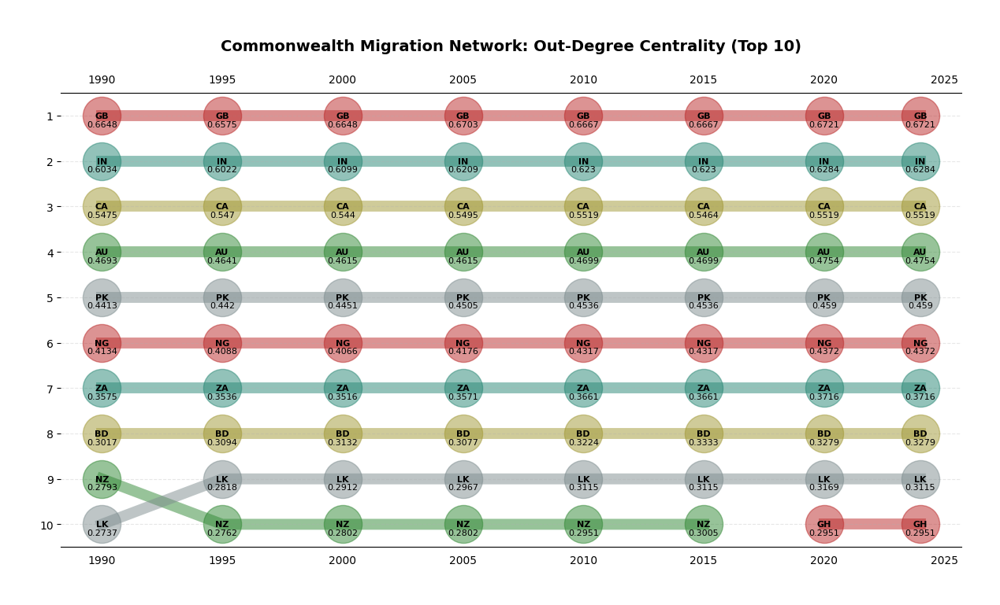

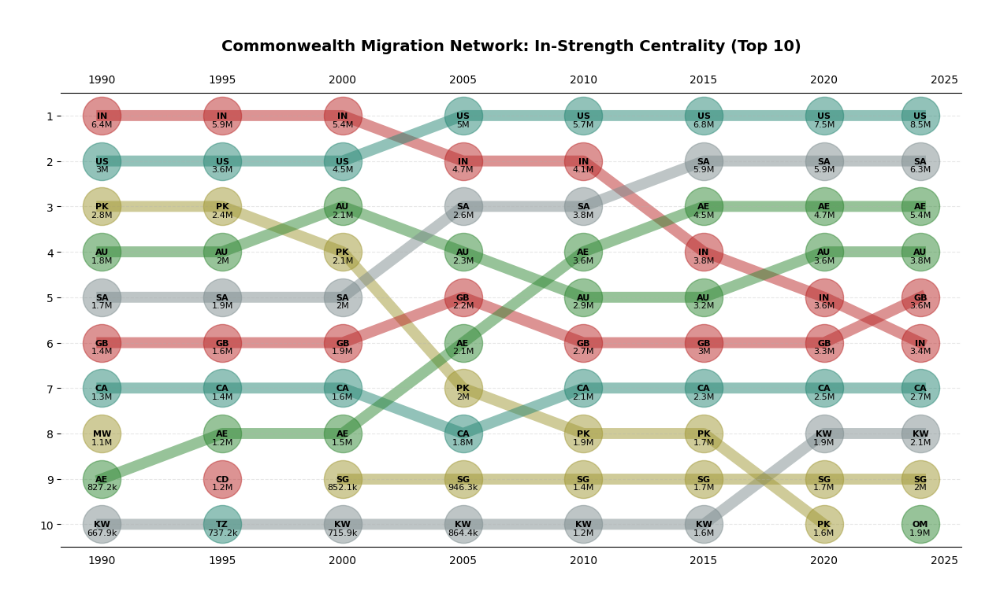

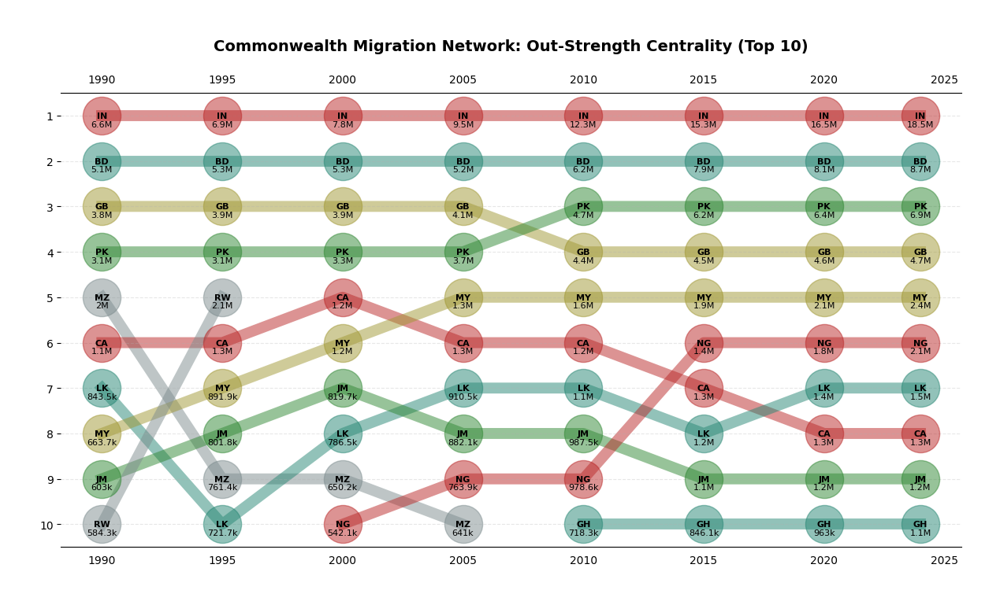

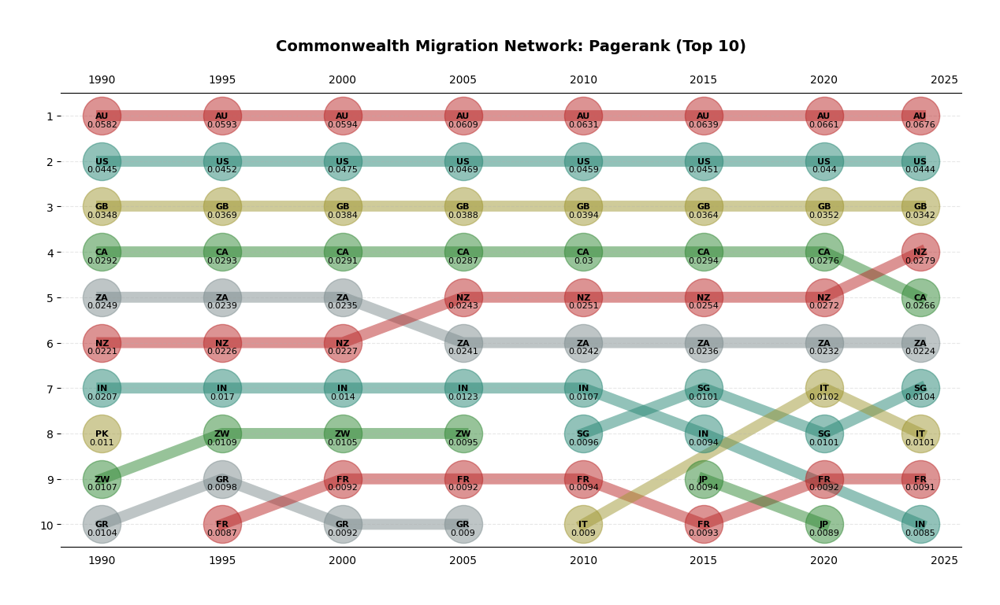

In [20]:
df_metricas = pd.DataFrame() # Uno solo para todo el período
dicc_df_centralidad = {} # Un df por año
for año in AÑOS:
    metricas_cw_mundo, df_top_año  = fa.metricas_red(
        df_migras_orig_cw.query('año == @año').copy(),
        10 # = n_ranking
    ) 
    df = pd.DataFrame([metricas_cw_mundo])    
    df.insert(0, 'año', año)
    
    df_metricas = pd.concat([df_metricas, df])
    
    dicc_df_centralidad[año] = df_top_año
    
df_metricas = df_metricas.reset_index(drop=True)
display(df_metricas)  

centralidades = {
    'cent_in_degree': ('top_10_cent_in_degree', 'cent_in_degree_valor'),
    'cent_out_degree': ('top_10_cent_out_degree', 'cent_out_degree_valor'),    
    'cent_in_strength': ('top_10_cent_in_strength', 'cent_in_strength_valor'),
    'cent_out_strength': ('top_10_cent_out_strength', 'cent_out_strength_valor'),
    'pagerank': ('top_10_pagerank', 'pagerank_valor')
}

resultados = []
for año, df in dicc_df_centralidad.items():
    for metrica, (col_pais, col_valor) in centralidades.items():
        df_temp = df[[col_pais, col_valor]].copy()
        df_temp.columns = ['pais', 'valor']
        df_temp['año'] = año
        df_temp['metrica'] = metrica
        df_temp['ranking'] = range(1, len(df_temp) + 1)
        resultados.append(df_temp)

df_ranking = pd.concat(resultados, ignore_index=True)
df_ranking = df_ranking[['año', 'metrica', 'ranking', 'pais', 'valor']]

nombres_rankings = {
    'cent_in_degree': 'In-Degree Centrality',
    'cent_out_degree': 'Out-Degree Centrality',    
    'cent_in_strength': 'In-Strength Centrality',
    'cent_out_strength': 'Out-Strength Centrality',
    'pagerank': 'Pagerank'
}

metricas_centralidad = df_ranking['metrica'].unique()


args = {
    'paleta_ranking': ['#ba2828', '#278774', '#a19834', '#318834', '#7e8d8f']
} # Por si hace falta ajustar
for metrica in metricas_centralidad:
    if metrica.endswith('strength'):
        convertir_valores = True
    else:
        convertir_valores = False
        
    fig = fa.crear_ranking(
        df_ranking[df_ranking['metrica'] == metrica].copy(),
        10, # Número de posiciones
        True, # Registrar puntuación,
        convertir_valores,
        f'Commonwealth Migration Network: {nombres_rankings[metrica]} (Top 10)\n', # Título
        f'evolución_ranking_{metrica}', # Nombre arhcivo
        **args
    )
    display(fig)

### **Migraciones hacia el interior y el exterior de la Commonwealth**

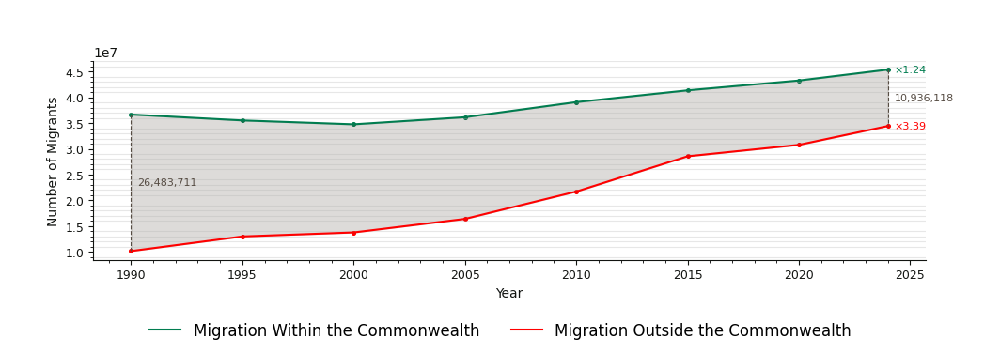

,año,migra_intra,migra_extra
0,1990,36654242,10170531
1,1995,35509212,13004963
2,2000,34755370,13781632
3,2005,36131688,16409241
4,2010,39062500,21713161
5,2015,41344932,28553576
6,2020,43252084,30772092
7,2024,45363402,34427284


In [21]:
df_migras_orig_cw['migra_intra_cw'] = (
    df_migras_orig_cw['iso2_orig'].isin(CONJ_MIEMBROS_CW) &
    df_migras_orig_cw['iso2_des'].isin(CONJ_MIEMBROS_CW)
)

# Obtenemos el número de migrantes en cada dirección (intra, extra)
migra_intra_cw = []
migra_extra_cw = []

for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año')
    migra_intra_cw.append(df_año.query('migra_intra_cw')['migrantes'].sum())
    migra_extra_cw.append(df_año.query('~migra_intra_cw')['migrantes'].sum())

df_compar_migra_cw = pd.DataFrame({
    'año': AÑOS,
    'migra_intra': migra_intra_cw,
    'migra_extra': migra_extra_cw,
})

dicc_tex_ref = {
    'migra_intra': 'Migration Within the Commonwealth',#'Migración al interior de la Commonwealth',
    'migra_extra': 'Migration Outside the Commonwealth',#'Migración hacia el exterior de la Commonwealth',
}
colores_var = {'migra_intra': '#017d50', 'migra_extra': '#ff0000'}


fig_intra_extra, _ = fa.graficar_comparacion_migras(
    df_compar_migra_cw,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_intra_extra_cw',
    **{'color_area': '#554b42'}
)

display(fig_intra_extra)
display(df_compar_migra_cw)

#### **Mapas de las migraciones hacia el exterior y el interior de la Commonwealth 1990-2024**

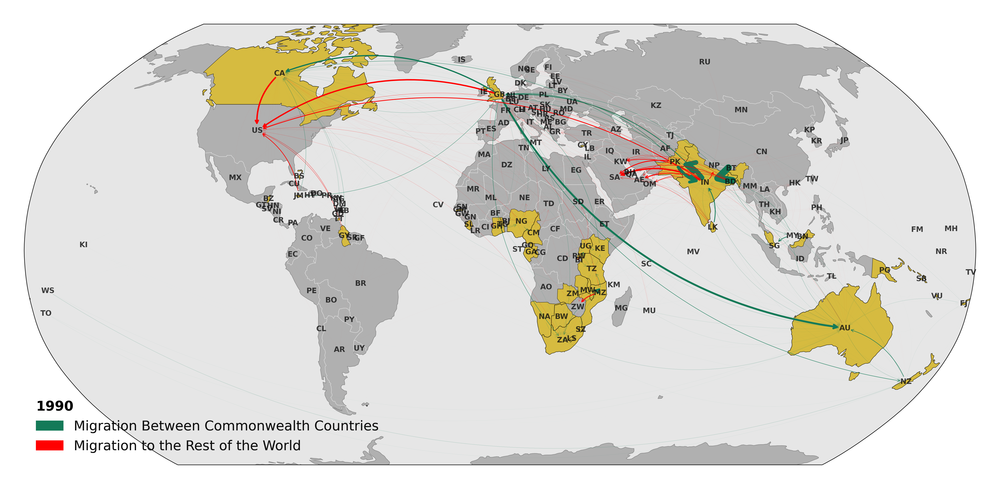

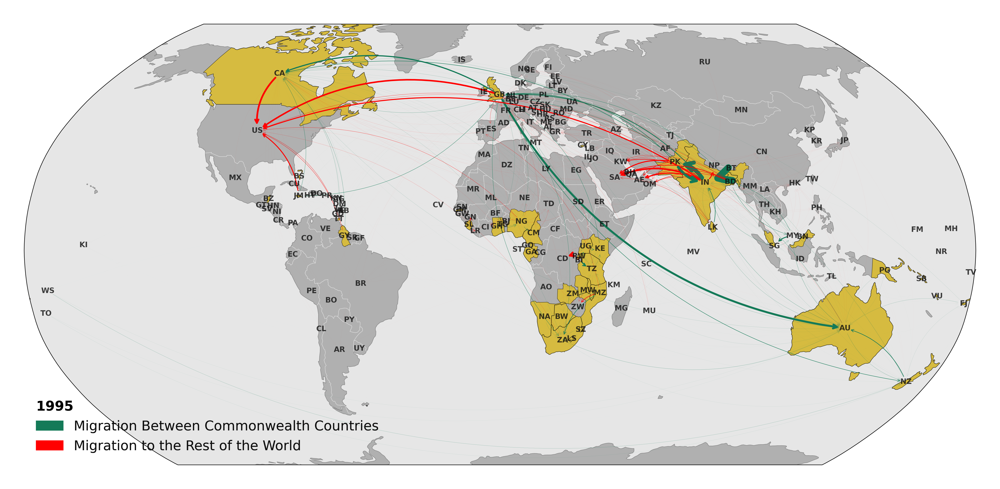

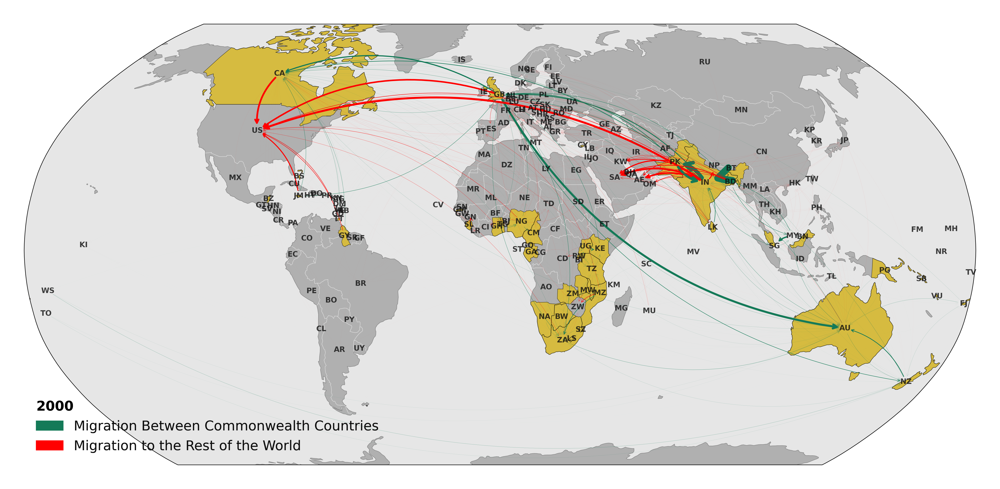

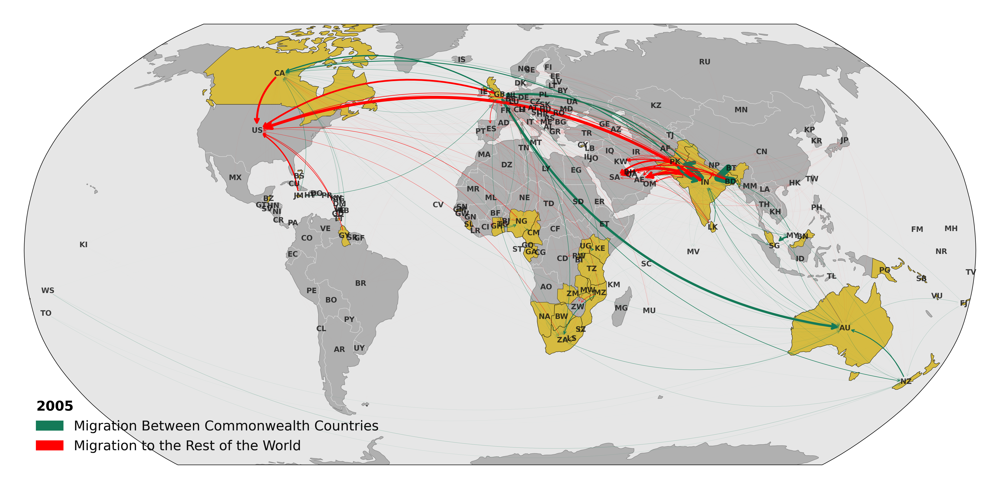

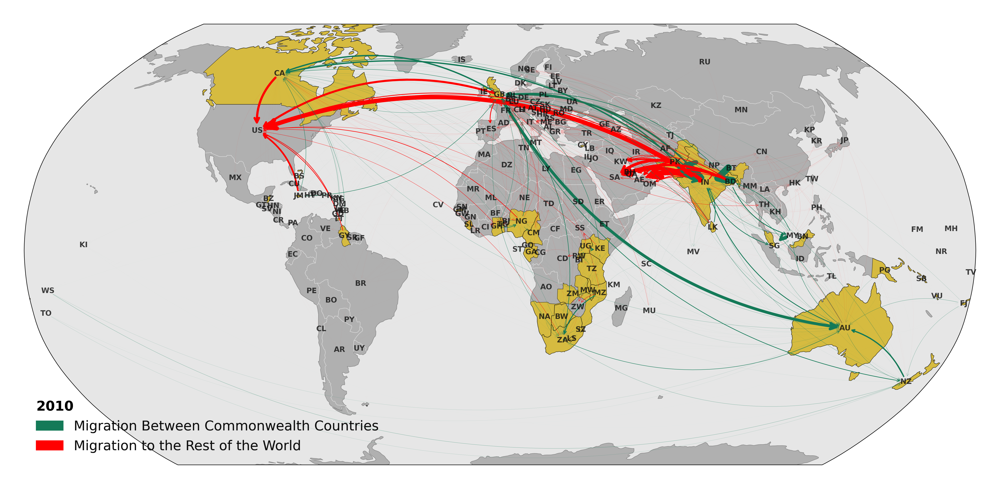

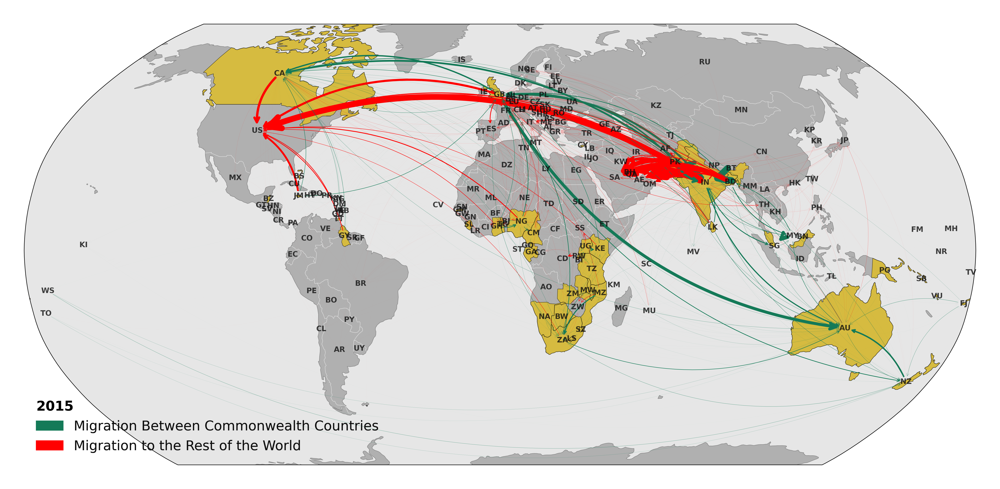

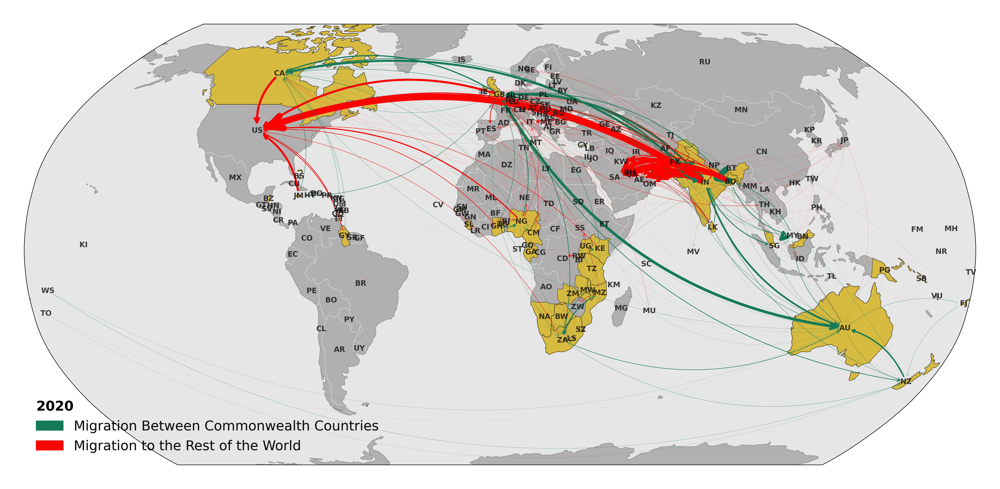

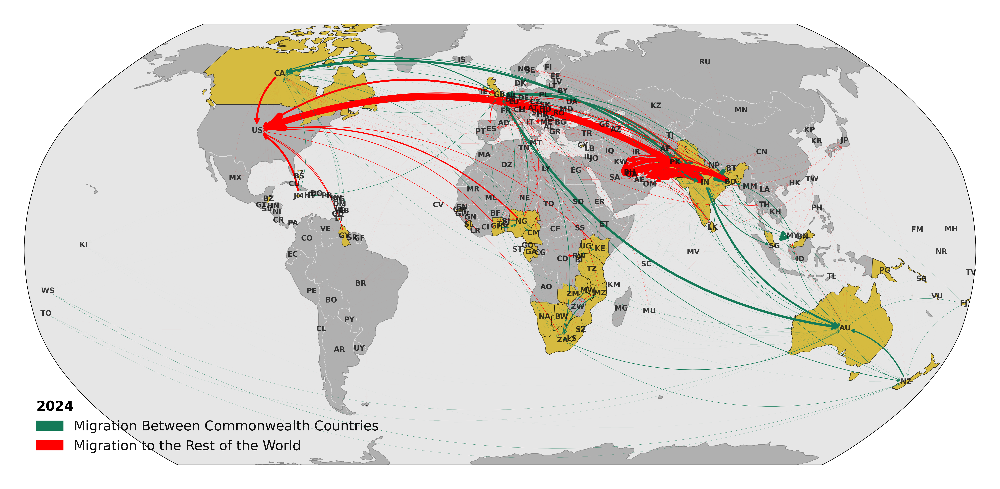

In [22]:
for año in AÑOS: # Permite detectar rapidamente los cambios más importantes
    fig = fa.graficar_red_cw(
        df_migras_orig_cw.query('año == @año'),
        None,
        set(DICC_ISO3_MIEMBROS_CW.values()),
        'migra_intra_cw',
        'Migration Between Commonwealth Countries', # 'Migración entre países de la Commonwealth',
        'Migration to the Rest of the World', # 'Migración hacia el resto del mundo',
        f'red_migra_cw_mundo_{str(año)}', # titulo archivo salida
    )
    display(fig)

#### **Principales destinos fuera de la Commonwealth durante el período 1990-2024**

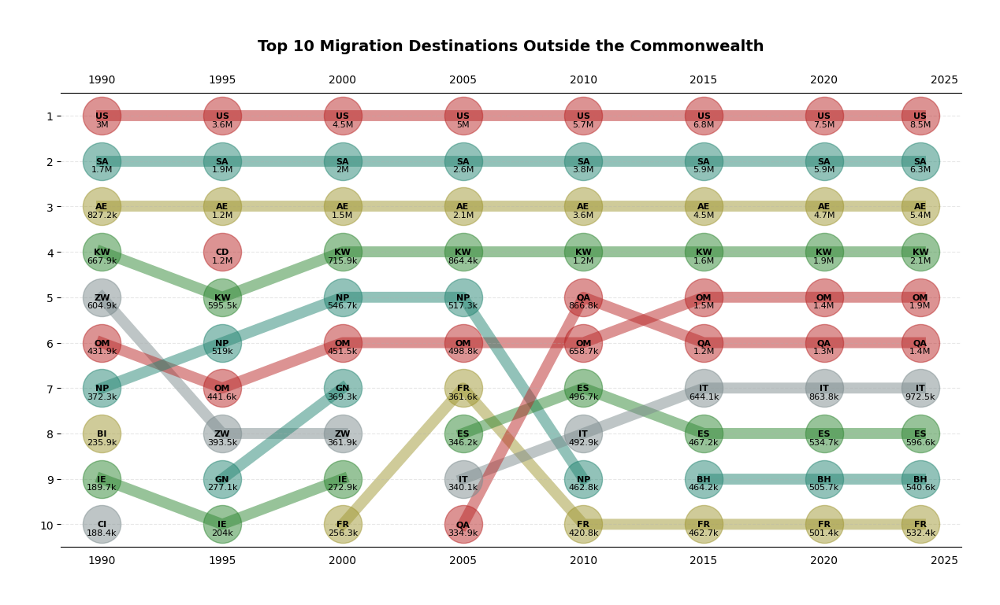

In [23]:
cols = ['año', 'iso2_des', 'migrantes']
df_ppales_destinos_extra_cw = df_migras_orig_cw.query('~migra_intra_cw').copy()[cols]
df_ppales_destinos_extra_cw = (
    df_ppales_destinos_extra_cw.groupby(
        ['año', 'iso2_des'], as_index=False
    )['migrantes'].sum()
).sort_values(['año', 'migrantes'], ascending=[True, False])


df_top10_destinos = df_ppales_destinos_extra_cw.copy()

df_top10_destinos['posicion'] = (
    df_top10_destinos.groupby('año')['migrantes']
    .rank(method='first', ascending=False)
    .astype(int)
)

df_top10_destinos = (
    df_top10_destinos[df_top10_destinos['posicion'] <= 10]
    .sort_values(['año', 'posicion'])
    .reset_index(drop=True)
)

df_top10_destinos['valor'] = df_top10_destinos['migrantes'].map(
    lambda x: fa.convertir_valor(x, 1)
)
df_top10_destinos['categoria'] = 'destinos_extra_cw'

df_top10_destinos = df_top10_destinos[['año', 'categoria', 'posicion', 'iso2_des', 'valor', 'migrantes']] 

args = {'paleta_ranking': ['#ba2828', '#278774', '#a19834', '#318834', '#7e8d8f']}
fig = fa.crear_ranking(
    df_top10_destinos.copy(),
    10, # Número de posiciones
    True, # Registrar puntuación,
    False, # Ya convertí los valores
    'Top 10 Migration Destinations Outside the Commonwealth\n', # Título
    f'evolución_ranking_destinos_externos', # Nombre arhcivo
    **args
)
display(fig)

### **Migraciones entre países con idioma en común**

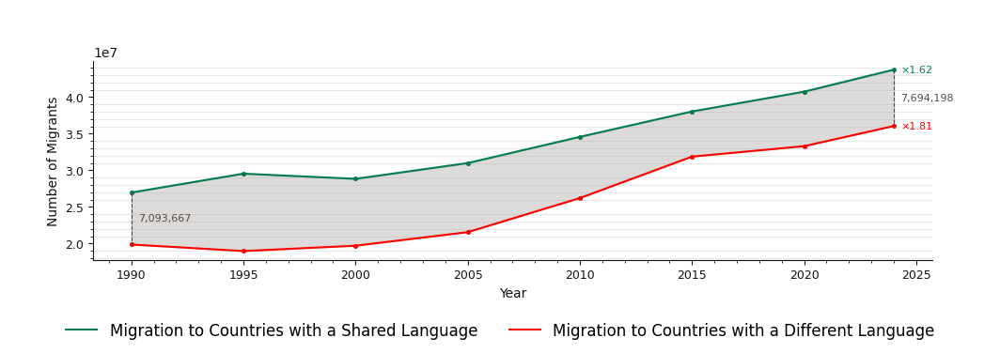

,año,migra_cw_idioma_comun,migra_cw_otro_idioma
0,1990,26959220,19865553
1,1995,29539880,18974295
2,2000,28832598,19704404
3,2005,30985455,21555474
4,2010,34565048,26210613
5,2015,38032065,31866443
6,2020,40732931,33291245
7,2024,43742442,36048244


In [24]:
# Obtenemos el número de migrantes en cada dirección (intra, extra)
migra_cw_idioma_comun = []
migra_cw_otro_idioma = []
for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año')
    migra_cw_idioma_comun.append(df_año.query('idioma_en_comun')['migrantes'].sum())
    migra_cw_otro_idioma.append(df_año.query('~idioma_en_comun')['migrantes'].sum())

df_compar_migra_cw_idioma = pd.DataFrame({
    'año': AÑOS,
    'migra_cw_idioma_comun': migra_cw_idioma_comun,
    'migra_cw_otro_idioma': migra_cw_otro_idioma
})

dicc_tex_ref = {
    'migra_cw_idioma_comun': 'Migration to Countries with a Shared Language',#'Migración a países con idioma en común',
    'migra_cw_otro_idioma': 'Migration to Countries with a Different Language',#'Migración a países con distinto idioma'
}
colores_var = {'migra_cw_idioma_comun': '#017d50', 'migra_cw_otro_idioma': '#ff0000'}

fig, eje = fa.graficar_comparacion_migras(
    df_compar_migra_cw_idioma,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_intra_cw_idioma',
    **{'color_area': '#554b42'}
)
display(fig)
display(df_compar_migra_cw_idioma)

### **Direcciones de la migración con origen en la Commonwealth**

Verificación de que la clasificación es exhaustiva y no se superponen categorías.

In [25]:
display(df_migras_orig_cw.query('a_colonizador & metropoli_comun'))
display(df_migras_orig_cw.query('a_colonizador & de_colonizador'))
display(df_migras_orig_cw.query('de_colonizador & metropoli_comun'))

,cod_orig,iso2_orig,iso3_orig,origen_ES,origen_EN,region_orig_ES,region_orig_EN,subregion_orig_ES,subregion_orig_EN,poblacion_orig,...,sin_litoral_des,lon_des,lat_des,año,migrantes,idioma_en_comun,a_colonizador,de_colonizador,metropoli_comun,migra_intra_cw


,cod_orig,iso2_orig,iso3_orig,origen_ES,origen_EN,region_orig_ES,region_orig_EN,subregion_orig_ES,subregion_orig_EN,poblacion_orig,...,sin_litoral_des,lon_des,lat_des,año,migrantes,idioma_en_comun,a_colonizador,de_colonizador,metropoli_comun,migra_intra_cw


,cod_orig,iso2_orig,iso3_orig,origen_ES,origen_EN,region_orig_ES,region_orig_EN,subregion_orig_ES,subregion_orig_EN,poblacion_orig,...,sin_litoral_des,lon_des,lat_des,año,migrantes,idioma_en_comun,a_colonizador,de_colonizador,metropoli_comun,migra_intra_cw


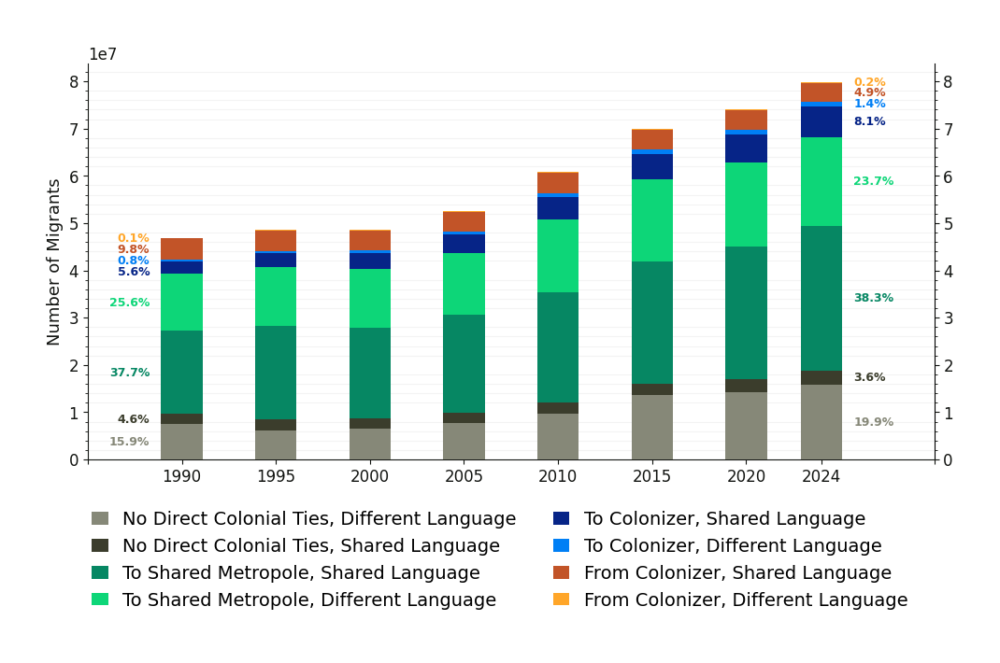

,año,migra_colon_comun,migra_colon_otro,migra_pot_comun,migra_pot_otro,migra_metro_comun,migra_metro_otro,migra_novin_comun,migra_novin_otro,total
0,1990,2608108,372356,4570164,47586,17630285,12009766,2150663,7435845,46824773
1,1995,2945050,447359,4418756,69226,19907815,12316249,2268259,6141461,48514175
2,2000,3356881,538679,4222508,90854,19111235,12557407,2141974,6517464,48537002
3,2005,3982584,659915,4163268,116830,20642060,13092690,2197543,7686039,52540929
4,2010,4769686,815091,4252768,153288,23195892,15519931,2346702,9722303,60775661
5,2015,5349971,907808,4237262,150178,25941545,17276342,2503287,13532115,69898508
6,2020,5963167,1003463,4065682,151516,27967816,17853459,2736266,14282807,74024176
7,2024,6434870,1082979,3870702,180830,30541179,18909166,2895691,15875269,79790686


In [69]:
# Obtenemos el número de migrantes en cada posible dirección
migra_cw_col_ic = [] # a colonizador - idioma comun 
migra_cw_col_io = [] # a colonizador - otro idioma  
migra_cw_met_ic = [] # a metro_comun - idioma comun
migra_cw_met_io = [] # a metro_comun - otro idioma
migra_cw_novin_ic = [] # a no_vinc_col - idioma comun
migra_cw_novin_io = [] # a no_vinc_col - otro idioma
migra_cw_pot_ic = [] # desde colonizador - idioma comun 
migra_cw_pot_io = [] # desde colonizador - otro idioma  


def clasificar_migracion_cw(fila):
    if fila['a_colonizador']:
        if fila['idioma_en_comun']:
            return 'COL-IC'
        else:
            return 'COL-IO'
    
    elif fila['de_colonizador']: # Desde GB
        if fila['idioma_en_comun']:
            return 'POT-IC'
        else:
            return 'POT-IO' 
        
    elif fila['metropoli_comun']: 
        if fila['idioma_en_comun']:
            return 'MET-IC'    
        else:
            return 'MET-IO'
            
    elif not fila['metropoli_comun']:        
        if fila['idioma_en_comun']:
            return 'NOVIN-IC'     
        else:
            return 'NOVIN-IO'
    else:
        raise ValueError(f"Caso no contemplado: {fila}")


for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año').copy()
    df_año['tipo_migra'] = df_año.apply(clasificar_migracion_cw, axis=1)    
    migra_cw_col_ic.append(df_año.query("tipo_migra == 'COL-IC'")['migrantes'].sum())
    migra_cw_col_io.append(df_año.query("tipo_migra == 'COL-IO'")['migrantes'].sum())    
    migra_cw_pot_ic.append(df_año.query("tipo_migra == 'POT-IC'")['migrantes'].sum())
    migra_cw_pot_io.append(df_año.query("tipo_migra == 'POT-IO'")['migrantes'].sum())    
    migra_cw_met_ic.append(df_año.query("tipo_migra == 'MET-IC'")['migrantes'].sum())
    migra_cw_met_io.append(df_año.query("tipo_migra == 'MET-IO'")['migrantes'].sum())    
    migra_cw_novin_ic.append(df_año.query("tipo_migra == 'NOVIN-IC'")['migrantes'].sum())
    migra_cw_novin_io.append(df_año.query("tipo_migra == 'NOVIN-IO'")['migrantes'].sum())


# Df con las migraciones en cada direccion
df_compar_direcciones_migra_cw = pd.DataFrame({
    'año': AÑOS,
    'migra_colon_comun': migra_cw_col_ic,
    'migra_colon_otro': migra_cw_col_io,    
    'migra_pot_comun': migra_cw_pot_ic,
    'migra_pot_otro': migra_cw_pot_io,
    'migra_metro_comun': migra_cw_met_ic,
    'migra_metro_otro': migra_cw_met_io,    
    'migra_novin_comun': migra_cw_novin_ic,
    'migra_novin_otro': migra_cw_novin_io,
})
# Agrego el total en cada año
df_compar_direcciones_migra_cw['total'] = df_compar_direcciones_migra_cw.iloc[:, 1:].sum(axis=1)

# Configuración de la visualización
dicc_tex_ref = {    
    'migra_colon_comun': 'To Colonizer, Shared Language',
    'migra_colon_otro': 'To Colonizer, Different Language',
    'migra_pot_comun': 'From Colonizer, Shared Language',
    'migra_pot_otro': 'From Colonizer, Different Language',
    'migra_metro_comun': 'To Shared Metropole, Shared Language',
    'migra_metro_otro': 'To Shared Metropole, Different Language',  
    'migra_novin_comun': 'No Direct Colonial Ties, Shared Language',
    'migra_novin_otro': 'No Direct Colonial Ties, Different Language',
}

# colores_var = {
#     'migra_novin_otro': '#868878',#'#8e9e8b',
#     'migra_novin_comun': '#3b3d2c', 
#     'migra_metro_comun': '#068763',
#     'migra_colon_otro': '#007ff5', 
#     'migra_metro_otro': '#0dd678',#'#d1b039',
#     'migra_pot_otro': '#c8c100',
#     'migra_pot_comun': '#a72323',          
#     'migra_colon_comun': '#062487',   
# }

colores_var = {
    'migra_novin_otro': '#868878',#'#8e9e8b',
    'migra_novin_comun': '#3b3d2c', 
    'migra_metro_comun': '#068763', 
    'migra_metro_otro': '#0dd678',#'#d1b039',
    'migra_colon_comun': '#062487',          
    'migra_colon_otro': '#007ff5',
    'migra_pot_comun': '#c25428',
    'migra_pot_otro': '#ffa629',
}



args = {
    'tam_tex_pct': 9,
    'tam_marcas_ejes': 12,
    'tam_ref': 14,
    'ubicacion_refs': (.5, -.27),
    'tam_fig': (10, 5),
    'grosor_barras': 2.2,
    'margen_etq_pct': 1.7,
    # 'cat_a_ajustar': 'migra_colon_comun', # Para bajar un poquiito el texto de los pct y que no se pisen
}

# Barras apiladas
fig_red_cw, _ = fa.graficar_barras_migras(
    df_compar_direcciones_migra_cw,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_direcciones_cw',
    **args
)
# Muestro el gráfico y la tabla con datos
display(fig_red_cw)
display(df_compar_direcciones_migra_cw)

##### **Composición de la red migratoria con origen en la COmmonwealth**

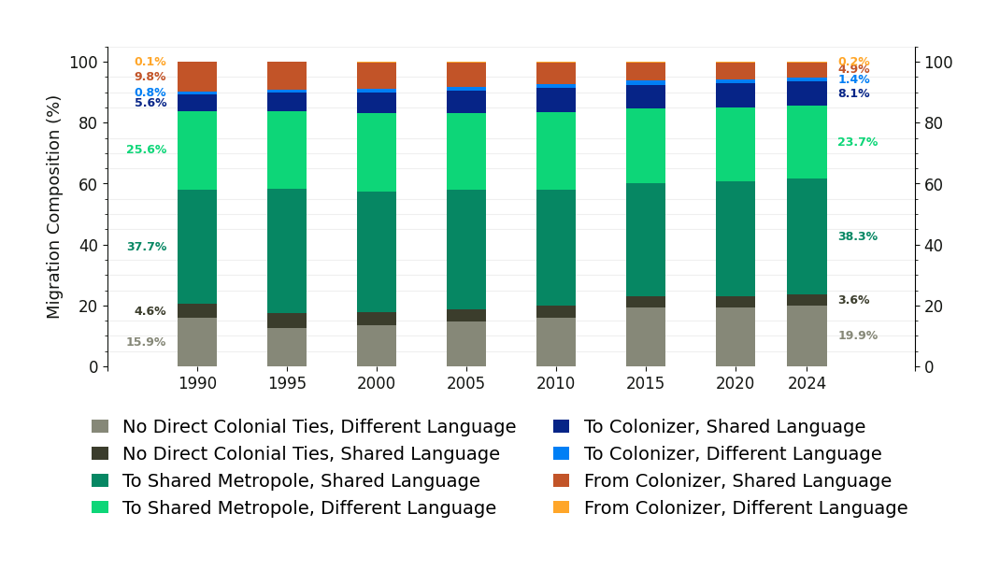

In [70]:
args = {
    'tam_tex_pct': 9,
    'tam_marcas_ejes': 12,
    'tam_ref': 14,
    'ubicacion_refs': (.5, -.34),
    'grosor_barras': 2.2,
    'margen_etq_pct': 1.7,
}

# Barras 100 pct
fig_red_cw_pct, _ = fa.graficar_composicion_migras(
    df_compar_direcciones_migra_cw,
    dicc_tex_ref,
    'Migration Composition (%)',
    colores_var,
    'migracion_direcciones_cw_100pct',
    **args
)
# Muestro el gráfico y la tabla con datosb
display(fig_red_cw_pct)

###### **Emigrantes desde GB** 

In [89]:
#1990
df_temp = df_migras_orig_cw.query("iso2_orig == 'GB' & año == 1990").copy()
totales_desde_gb_1990 = df_temp['migrantes'].sum()
totales_hacia_ex_colonias_1990 =(
    df_temp[df_temp['iso2_des']
    .isin(CONJ_MIEMBROS_CW)]['migrantes']
    .sum()
)

#2024
df_temp = df_migras_orig_cw.query("iso2_orig == 'GB' & año == 2024").copy()
totales_desde_gb_2024 = df_temp['migrantes'].sum()
totales_hacia_ex_colonias_2024 =(
    df_temp[df_temp['iso2_des']
    .isin(CONJ_MIEMBROS_CW)]['migrantes']
    .sum()
)

print(
    f'Total emigrantes desde GB 1990: {totales_desde_gb_1990}.\n'
    f'Total hacia ex-colonias: {totales_hacia_ex_colonias_1990}.\n'
    f'Total emigrantes desde GB 2024: {totales_desde_gb_2024}.\n'
    f'Total hacua ex-colonias: {totales_hacia_ex_colonias_2024}.\n'
)

Total emigrantes desde GB 1990: 6082677.
Total hacia ex-colonias: 4617750.
Total emigrantes desde GB 2024: 6718499.
Total hacua ex-colonias: 4051532.



In [88]:
df_migras_orig_cw.query("a_colonizador & iso2_des != 'GB'")['iso2_des']

64       FR
91       FR
157      PT
319      FR
354      PT
         ..
18379    PT
18560    BE
18723    NL
19187    PT
19412    PT
Name: iso2_des, Length: 72, dtype: object

### **Migraciones según idioma en común y pertenencia a la Commonwealth en 1990 y 2024**

{'AE': 'United Arab Emirates', 'AR': 'Argentina', 'AU': 'Australia', 'BD': 'Bangladesh', 'BH': 'Bahrain', 'BI': 'Burundi', 'CA': 'Canada', 'CI': 'Côte d’Ivoire', 'CM': 'Cameroon', 'CN': 'China', 'CY': 'Cyprus', 'FJ': 'Fiji', 'FR': 'France', 'GB': 'United Kingdom of Great Britain and Northern Ireland', 'GH': 'Ghana', 'GR': 'Greece', 'GY': 'Guyana', 'HK': 'China, Hong Kong Special Administrative Region', 'IE': 'Ireland', 'IN': 'India', 'JM': 'Jamaica', 'JP': 'Japan', 'KE': 'Kenya', 'KW': 'Kuwait', 'LB': 'Lebanon', 'LK': 'Sri Lanka', 'LS': 'Lesotho', 'MU': 'Mauritius', 'MW': 'Malawi', 'MY': 'Malaysia', 'MZ': 'Mozambique', 'NG': 'Nigeria', 'NP': 'Nepal', 'NZ': 'New Zealand', 'OM': 'Oman', 'PK': 'Pakistan', 'PT': 'Portugal', 'RU': 'Russian Federation', 'RW': 'Rwanda', 'SA': 'Saudi Arabia', 'SD': 'Sudan', 'SG': 'Singapore', 'TG': 'Togo', 'TT': 'Trinidad and Tobago', 'TZ': 'United Republic of Tanzania', 'UG': 'Uganda', 'US': 'United States of America', 'ZA': 'South Africa', 'ZW': 'Zimbabwe'}.

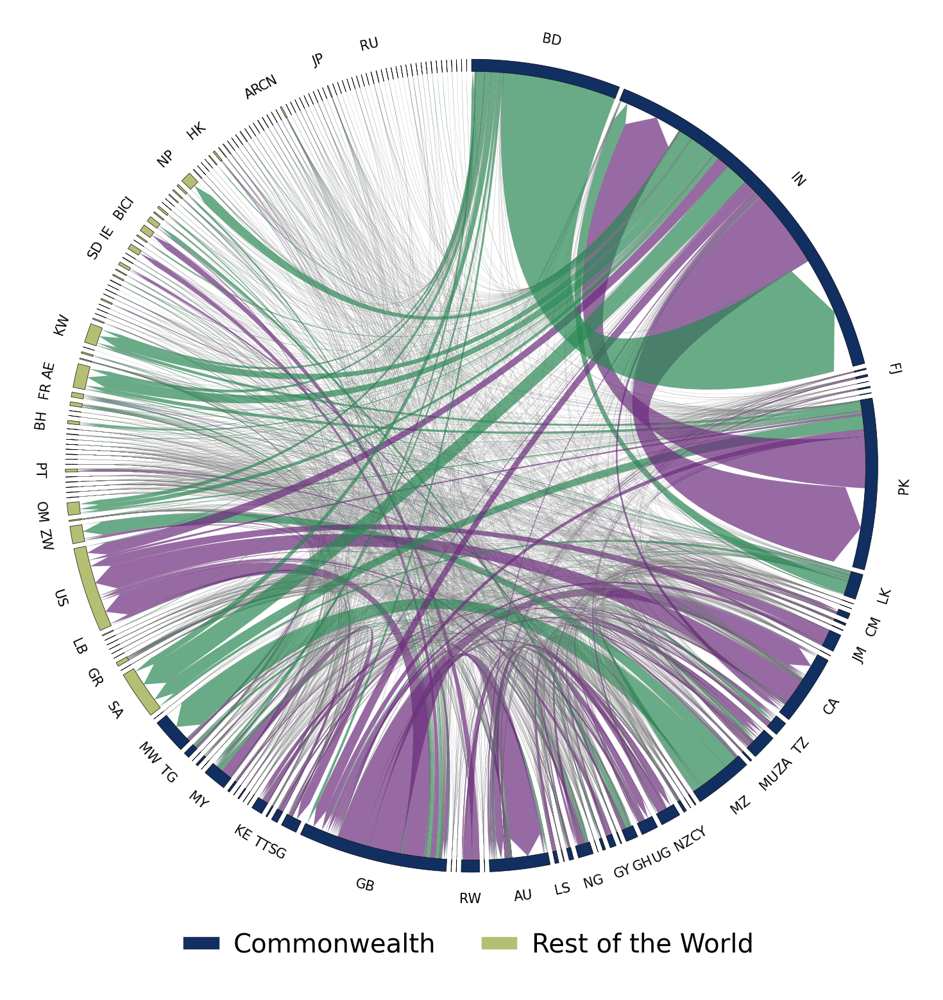

{'AE': 'United Arab Emirates', 'AR': 'Argentina', 'AU': 'Australia', 'BD': 'Bangladesh', 'BH': 'Bahrain', 'BJ': 'Benin', 'BN': 'Brunei Darussalam', 'CA': 'Canada', 'CH': 'Switzerland', 'CM': 'Cameroon', 'CN': 'China', 'DE': 'Germany', 'DK': 'Denmark', 'ES': 'Spain', 'FR': 'France', 'GB': 'United Kingdom of Great Britain and Northern Ireland', 'GH': 'Ghana', 'GR': 'Greece', 'GY': 'Guyana', 'ID': 'Indonesia', 'IE': 'Ireland', 'IN': 'India', 'IT': 'Italy', 'JM': 'Jamaica', 'KE': 'Kenya', 'KW': 'Kuwait', 'LK': 'Sri Lanka', 'MT': 'Malta', 'MU': 'Mauritius', 'MW': 'Malawi', 'MY': 'Malaysia', 'MZ': 'Mozambique', 'NG': 'Nigeria', 'NO': 'Norway', 'NP': 'Nepal', 'NZ': 'New Zealand', 'OM': 'Oman', 'PK': 'Pakistan', 'QA': 'Qatar', 'RW': 'Rwanda', 'SA': 'Saudi Arabia', 'SG': 'Singapore', 'SS': 'South Sudan', 'TG': 'Togo', 'TT': 'Trinidad and Tobago', 'UG': 'Uganda', 'US': 'United States of America', 'ZA': 'South Africa', 'ZW': 'Zimbabwe'}. 2024:


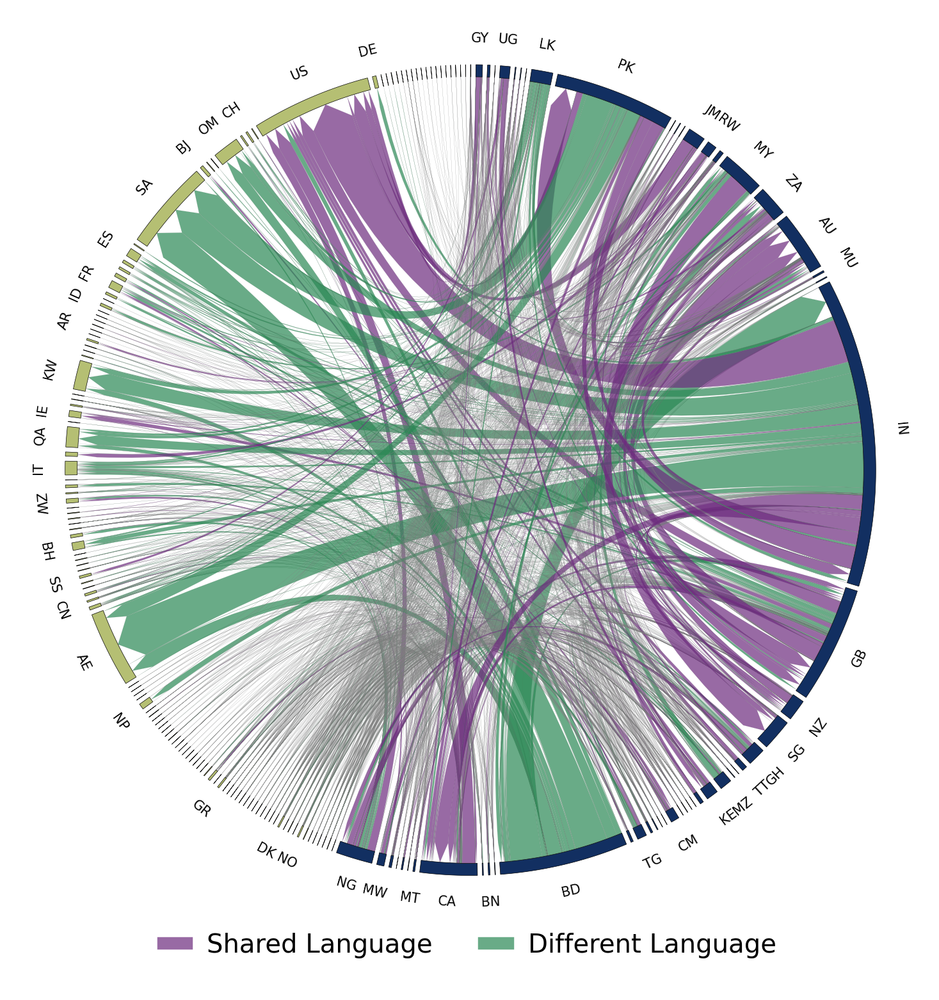

In [79]:
args = {
    'color_nodos_a_destacar': '#122f61',#'#1b458f',
    'color_resto_nodos': '#b5bf73',#'#b3b889',#b4a66c',
    'color_a_idioma_comun': '#6d2b7e',#004126',#e22739',
    'color_a_otro_idioma': '#2a8854'#ff0000'#008b4e',
}

fig_90, paises_visibles_90 = fa.graficar_cuerdas_cw(
    df_migras_orig_cw, # datos
    1990, # año
    (27, 'ppales'), # umbral inicial (27)
    LISTA_MIEMBROS_CW, # nodos a destacar
    'diagrama_cuerdas_migra_cw',
    DICC_NOMBRES_PAISES,
    **args | 
    { # Para manejar con precisión la visibilidad 
        'incluir_pais': [
            'SD', 'IE', 'BI', 'CI', 'FR', 'GR', 'BH', 'PT',
            'CN', 'JP', 'RU', 'HK', 'AR', 'FJ', 'CM',
            'MU', 'CY', 'LB', 'TT', 'LS', 'GY', 'TG'
        ],
        'ocultar_pais': []
    } | 
    {'imprimir_referencias': True} |
    {'refs_a_imprimir': 'miembros', 'tam_tex_ref': 29}
)

fig_24, paises_visibles_24 = fa.graficar_cuerdas_cw(
    df_migras_orig_cw, # datos
    2024, # año
    (27, 'ppales'), # umbral
    LISTA_MIEMBROS_CW, # nodos a destacar
    'diagrama_cuerdas_migra_cw',
    DICC_NOMBRES_PAISES,
    **args |     
    { # Para manejar con precisión la visibilidad 
        'incluir_pais': [
            'DE', 'GY', 'CH', 'BJ', 'ES', 'FR', 'CN',
            'AR', 'IE', 'ID', 'ZW', 'NP', 'TT', 'GR',
            'BN', 'SS', 'BH', 'DK', 'NO', 'MW', 'MT',
            'MU',
        ],
        'ocultar_pais': []
    } |  
    {'imprimir_referencias': True} |
    {'refs_a_imprimir': 'idioma', 'tam_tex_ref': 29}
)


print(f'{paises_visibles_90}. 1990:')
display(fig_90)
print(f'{paises_visibles_24}. 2024:')
display(fig_24)